# Maximum common substructure

This notebook uses SMSD 8.2.0 or later to find the maximum common substructure
(MCS) of small drug-like molecules. It compares the two objectives, shows what
a stopped search returns, changes the chemistry rules, computes MCS similarity,
exports a SMARTS pattern and finds a common graph across a short series. Every
result keeps its status, so a proved maximum is never confused with a partial
answer. All molecules are written inline.

IPython and pandas are optional. Without IPython, drawings are summarised as
text; without pandas, the similarity table is printed row by row.

## Setup

Run the next cell first in Colab or local Jupyter. It installs SMSD Pro and
the notebook's missing table or numerical dependencies into the current
kernel, using that kernel's Python. An already installed SMSD 8.2.0 or later
is kept. Installation needs internet access; the chemistry examples use inline
inputs. No wheel upload or copied setup cell is needed.

If an older SMSD is already imported, restart the kernel before running
setup. See [Installation](https://asad.github.io/SMSD/HOWTO-INSTALL/).


In [1]:
# Run this cell first in Colab or a local Jupyter kernel.
import importlib
import importlib.metadata
import importlib.util
import subprocess
import sys

if sys.version_info < (3, 12):
    raise RuntimeError("Select a Python 3.12 or later kernel for SMSD Pro wheels")

try:
    _smsd_version = importlib.metadata.version("smsd")
except importlib.metadata.PackageNotFoundError:
    _smsd_version = "0.0.0"
_smsd_parts = tuple(int(part) for part in _smsd_version.split(".")[:3]
                    if part.isdigit())
_requirements = []
if importlib.util.find_spec("smsd") is None or _smsd_parts < (8, 2, 0):
    if "smsd" in sys.modules:
        raise RuntimeError("Restart the kernel, then run this setup cell before importing SMSD")
    _requirements.append("smsd>=8.2.0,<9")
if _requirements:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet", "--only-binary=:all:",
         *_requirements], check=True,
    )
    importlib.invalidate_caches()
_optional_packages = {'pandas': 'pandas>=2.0,<4'}
_optional_requirements = [_package for _module, _package in _optional_packages.items()
                          if importlib.util.find_spec(_module) is None]
if _optional_requirements:
    try:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "--quiet", "--only-binary=:all:",
             *_optional_requirements], check=True,
        )
    except subprocess.CalledProcessError:
        print("Some optional packages have no compatible wheel or could not be downloaded. "
              "The affected cells will report what is missing; SMSD remains available.")
    importlib.invalidate_caches()
import smsd
print("Using SMSD", smsd.__version__)


Using SMSD 8.2.0


In [2]:
# Responsive figures with a caption, an accessible image and an SVG fallback.
import base64
from html import escape


def show_svg(svg_text, description, max_width=800):
    image_uri = "data:image/svg+xml;base64," + base64.b64encode(
        svg_text.encode("utf-8")).decode("ascii")
    figure = (
        f'<figure style="margin:1em 0;max-width:{int(max_width)}px">'
        f'<img src="{image_uri}" alt="{escape(description, quote=True)}" '
        'style="display:block;width:100%;height:auto;box-sizing:border-box;'
        'background:#fff;border:1px solid #d5dce3;border-radius:8px;padding:16px">'
        f'<figcaption style="margin-top:0.6em;line-height:1.5">{escape(description)}</figcaption>'
        '</figure>'
    )
    try:
        from IPython.display import display
    except ImportError:
        print(description)
    else:
        display({"text/html": figure, "image/svg+xml": svg_text,
                 "text/plain": description}, raw=True,
                metadata={"image/svg+xml": {"alt": description}})


def show_table(frame):
    try:
        from IPython.display import display
    except ImportError:
        print(frame.to_string())
    else:
        display(frame)


In [3]:
import re

import smsd

print("SMSD", smsd.__version__)
_installed = tuple(int(part) for part in re.findall(r"\d+", smsd.__version__)[:3])
if _installed < (8, 2, 0):
    raise RuntimeError("This notebook needs SMSD 8.2.0 or later")

try:
    from IPython.display import SVG, display
except ImportError:
    SVG = display = None
    print("IPython is not installed; drawings are summarised as text")

SMSD 8.2.0


In [4]:
query = "CC(C)Cc1ccc(cc1)C(C)C(=O)O"  # ibuprofen
target = "COc1ccc2cc(ccc2c1)C(C)C(=O)O"  # naproxen
result = smsd.MCS.find(query).with_timeout(1000).match(target)

print("status:", result.status.name, "| optimal:", result.optimal,
      "| complete:", result.complete)
print("common atoms:", result.best.atom_count)
print("common graph:", result.best.to_smiles(query))
assert result.optimal and result.best.atom_count == 14

status: COMPLETED | optimal: True | complete: True
common atoms: 14
common graph: C(C(C)c1ccc(CCC)cc1)(=O)O


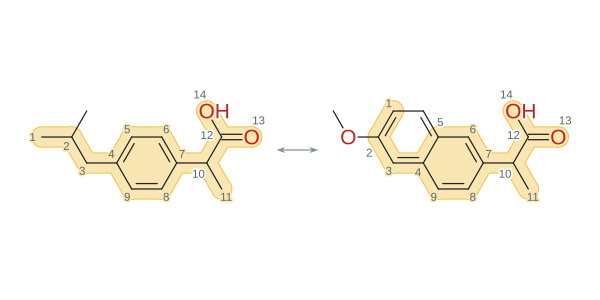

In [5]:
from smsd.highlight import mcs_svg

svg_text = mcs_svg(query, target, result, width=600, height=300)
if display is not None:
    show_svg(svg_text, "Query and target with the common substructure highlighted; "
             "the SVG title records search status and proof flags.")
else:
    print(re.search(r"<title>(.*?)</title>", svg_text).group(1))

## Objectives and fragments

The default objective, MCIS, maximises common atoms and keeps every bond and
non-bond between them. MCES maximises common bonds and may leave out a bond
between two mapped atoms. The score counts atoms for MCIS and bonds for MCES,
so compare scores only within one objective. `with_fragments()` allows a
disconnected common graph; MCIS fragments can include isolated atoms.

In [6]:
cyclopropane, isobutane = "C1CC1", "CC(C)C"
induced = smsd.MCS.find(cyclopropane).match(isobutane)
edges = smsd.MCS.find(cyclopropane).with_objective(
    smsd.MCS.Objective.MCES).match(isobutane)
for label, found in (("MCIS", induced), ("MCES", edges)):
    best = found.best
    print(f"{label}: atoms {best.atom_count}, bonds {best.bond_count}, "
          f"score {found.score}, {best.to_smiles(cyclopropane)}")

ether, amine = "CCOCC", "CCNCC"  # diethyl ether, diethylamine
connected = smsd.MCS.find(ether).match(amine)
split = smsd.MCS.find(ether).with_fragments().match(amine)
print("connected:", connected.best.atom_count, "atoms")
print("fragments:", split.best.atom_count, "atoms", split.best.fragments,
      split.best.to_smiles(ether))

isolated = smsd.MCS.find("C.O").with_fragments().match("C.O")  # methane, water
print("isolated atoms in MCIS fragments:", isolated.best.fragments)

MCIS: atoms 2, bonds 1, score 2.0, CC
MCES: atoms 3, bonds 2, score 2.0, C(C)C
connected: 2 atoms
fragments: 4 atoms ((0, 1), (3, 4)) CC.CC
isolated atoms in MCIS fragments: ((0,), (1,))


## Partial results

A node limit, a time limit or a cancellation token can stop a search early. The
common graph found so far is still valid, but it is described as the maximum
only when `optimal` is true. Do not rely on the exact mapping of a stopped
search.

In [7]:
for limit in (2, 5, 20, 100):
    options = smsd.MCS.Options()
    options.timeout_ms = 2000
    options.node_limit = limit
    stopped = smsd.MCS.find(query).with_options(options).match(target)
    valid = smsd.MCS.validate_mapping(query, target, stopped.best, options) == []
    print(f"node_limit {limit}: {stopped.status.name} | optimal: {stopped.optimal} "
          f"| atoms: {stopped.best.atom_count} | valid: {valid}")

node_limit 2: LIMIT_REACHED | optimal: False | atoms: 2 | valid: True
node_limit 5: LIMIT_REACHED | optimal: False | atoms: 5 | valid: True
node_limit 20: LIMIT_REACHED | optimal: False | atoms: 13 | valid: True
node_limit 100: COMPLETED | optimal: True | atoms: 14 | valid: True


In [8]:
prepared = smsd.MCS.find(cyclopropane).with_timeout(1000)
everything = prepared.match_all(isobutane, limit=100)
capped = prepared.match_all(isobutane, limit=2)
canonical = {
    tuple(sorted(smsd.MCS.canonicalize_mapping(
        cyclopropane, isobutane, dict(match.atom_mapping)).items()))
    for match in everything.matches
}
print(len(everything.matches), "optimal mappings,", everything.status.name,
      "| complete:", everything.complete)
print("limit 2:", capped.status.name, "| optimal:", capped.optimal,
      "| complete:", capped.complete)
print("distinct up to symmetry:", sorted(canonical))

18 optimal mappings, COMPLETED | complete: True
limit 2: LIMIT_REACHED | optimal: True | complete: False
distinct up to symmetry: [((0, 0), (1, 1))]


## Chemistry rules

`options.chemistry` decides which atoms and bonds may correspond. Bond order,
aromaticity and the three ring options each change the common graph in a
different way.

In [9]:
def common_graph(first, second, **fields):
    options = smsd.MCS.Options()
    options.timeout_ms = 1000
    for name, value in fields.items():
        setattr(options.chemistry, name, value)
    found = smsd.MCS.find(first).with_options(options).match(second)
    if not found.found:
        return 0, "(none)"
    return found.best.atom_count, found.best.to_smiles(first)


naphthalene, styrene = "c1ccc2ccccc2c1", "C=Cc1ccccc1"
cases = [
    ("propene, propane: STRICT bond order", "C=CC", "CCC", {}),
    ("propene, propane: LOOSE bond order", "C=CC", "CCC",
     {"match_bond_order": smsd.BondOrderMode.LOOSE}),
    ("benzene, cyclohexa-1,3-diene: FLEXIBLE", "c1ccccc1", "C1=CCCC=C1", {}),
    ("benzene, cyclohexa-1,3-diene: STRICT", "c1ccccc1", "C1=CCCC=C1",
     {"aromaticity_mode": smsd.AromaticityMode.STRICT}),
    ("naphthalene, styrene: default", naphthalene, styrene, {}),
    ("naphthalene, styrene: complete_rings_only", naphthalene, styrene,
     {"complete_rings_only": True}),
    ("naphthalene, styrene: ring_matches_ring_only", naphthalene, styrene,
     {"ring_matches_ring_only": True}),
    ("naphthalene, styrene: ring_fusion_mode STRICT", naphthalene, styrene,
     {"ring_fusion_mode": smsd.RingFusionMode.STRICT}),
]
for label, first, second, fields in cases:
    atoms, smiles = common_graph(first, second, **fields)
    print(f"{label}: {atoms} atoms {smiles}")

propene, propane: STRICT bond order: 2 atoms CC
propene, propane: LOOSE bond order: 3 atoms C(=C)C
benzene, cyclohexa-1,3-diene: FLEXIBLE: 6 atoms c1ccccc1
benzene, cyclohexa-1,3-diene: STRICT: 0 atoms (none)
naphthalene, styrene: default: 8 atoms C(C)c1ccccc1
naphthalene, styrene: complete_rings_only: 6 atoms c1ccccc1
naphthalene, styrene: ring_matches_ring_only: 6 atoms c1ccccc1
naphthalene, styrene: ring_fusion_mode STRICT: 6 atoms C(CCC)CC


## MCS similarity

The MCS similarity is common atoms divided by query atoms plus target atoms
minus common atoms, computed here from `best.atom_count`.
`similarity_upper_bound` is a fast upper bound on it, and `screen_targets`
keeps every target whose bound reaches a threshold, so the targets it keeps
are confirmed with an MCS search.

In [10]:
benzoic_acid = "c1ccccc1C(=O)O"
library = {
    "methyl benzoate": "c1ccccc1C(=O)OC",
    "phenol": "c1ccc(O)cc1",
    "acetic acid": "CC(=O)O",
    "nicotinic acid": "c1ccncc1C(=O)O",
    "butane": "CCCC",
}
names, molecules = list(library), list(library.values())
query_atoms = smsd.parse_smiles(benzoic_acid).n
prepared = smsd.MCS.find(benzoic_acid).with_timeout(1000)
rows = []
for name, smiles, found in zip(names, molecules,
                               prepared.match_many(molecules, num_threads=1)):
    common = found.best.atom_count if found.found else 0
    target_atoms = smsd.parse_smiles(smiles).n
    rows.append({
        "molecule": name,
        "common atoms": common,
        "optimal": found.optimal,
        "MCS similarity": round(common / (query_atoms + target_atoms - common), 3),
        "upper bound": round(smsd.similarity_upper_bound(benzoic_acid, smiles), 3),
    })

try:
    import pandas as pd
except ImportError:
    print("pandas is not installed; printing the rows instead")
    for row in rows:
        print(row)
else:
    table = pd.DataFrame(rows)
    if display is not None:
        display(table)
    else:
        print(table.to_string(index=False))

kept = smsd.screen_targets(benzoic_acid, molecules, 0.7, num_threads=1)
print("bound keeps:", [names[index] for index in kept])
print("MCS confirms:", [names[index] for index in kept
                        if rows[index]["MCS similarity"] >= 0.7])

,molecule,common atoms,optimal,MCS similarity,upper bound
0,methyl benzoate,9,True,0.900,0.900
1,phenol,6,True,0.600,0.778
2,acetic acid,4,True,0.444,0.444
3,nicotinic acid,8,True,0.800,0.800
4,butane,4,True,0.444,0.444


bound keeps: ['methyl benzoate', 'phenol', 'nicotinic acid']
MCS confirms: ['methyl benzoate', 'nicotinic acid']


In [11]:
small_library = ["c1ccccc1O", "c1ccccc1N", "Cc1ccccc1", "CCO", "C1CCCCC1"]
for mode in (smsd.AromaticityMode.FLEXIBLE, smsd.AromaticityMode.STRICT):
    options = smsd.MCS.Options()
    options.timeout_ms = 1000
    options.chemistry.aromaticity_mode = mode
    exported = smsd.MCS.find("c1ccccc1O").with_options(options).match_with_smarts(
        "c1ccccc1N")  # phenol, aniline
    search = smsd.Substructure.smarts(exported.smarts).with_timeout(1000)
    hits = [smiles for smiles, found
            in zip(small_library, search.match_many(small_library, num_threads=1))
            if found.found]
    print(mode.name, "pattern:", exported.smarts)
    print("  library hits:", hits)

FLEXIBLE pattern: [#6]-,=,:1-,=,:[#6]-,=,:[#6]-,=,:[#6]-,=,:[#6]-,=,:[#6]1
  library hits: ['c1ccccc1O', 'c1ccccc1N', 'Cc1ccccc1', 'C1CCCCC1']
STRICT pattern: [#6;a]:1:[#6;a]:[#6;a]:[#6;a]:[#6;a]:[#6;a]1
  library hits: ['c1ccccc1O', 'c1ccccc1N', 'Cc1ccccc1']


mcs_svg cannot show this MCES result; drawing its selected graph


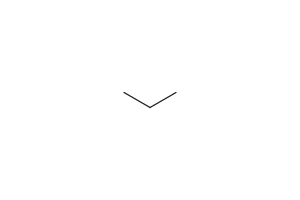

In [12]:
cyclopropene = "C1=CC1"  # its C=C has no partner bond of the same order in cyclopropane
mces_result = smsd.MCS.find(cyclopropene).with_objective(
    smsd.MCS.Objective.MCES).match(cyclopropane)
try:
    mcs_svg(cyclopropene, cyclopropane, mces_result)
except ValueError:
    print("mcs_svg cannot show this MCES result; drawing its selected graph")
selected = smsd.depict_svg(mces_result.best.to_graph(cyclopropene),
                           width=300, height=200)
if display is not None:
    show_svg(selected, "The selected common graph of the MCES result.", max_width=420)
else:
    print("selected graph:", mces_result.best.to_smiles(cyclopropene))

## A common graph across a series

`MCS.consensus` looks for a graph shared by all inputs, or by a fraction of
them set with `threshold`. The result is an approximate common graph, not
proved optimal, so `optimal` is always false.

In [13]:
series = {
    "phenethylamine": "c1ccccc1CCN",
    "2-phenylethanol": "c1ccccc1CCO",
    "phenylacetic acid": "c1ccccc1CC(=O)O",
    "2-methylphenethylamine": "Cc1ccccc1CCN",
}
common = smsd.MCS.consensus(list(series.values()))
print("common graph:", common.to_smiles(), "| support:", common.support_count,
      "of", len(series))
print("optimal:", common.optimal, "| complete:", common.complete)

common graph: C(C)c1ccccc1 | support: 4 of 4
optimal: False | complete: True


## Further reading

The [MCS chapter](https://asad.github.io/SMSD/guide/MCS/) of the user guide covers every
option shown here, with atom weights, reserved atoms, validation, tautomers and
the full options tables. Screening a library by MCS similarity is covered in
[Screening a library](https://asad.github.io/SMSD/guide/SCREENING/).